# Flora Image Classification (ResNet50)
This notebook trains a ResNet50 model to classify 104 flower species and exports the model and class mappings for deployment.

In [1]:
import numpy as np
import json
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

In [2]:
data_dir = '/kaggle/input/flower-classification-dataset/Flower Dataset'
target_size = (224, 224)
batch_size = 64

train_gen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

val_gen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    validation_split=0.2
)

df_train = train_gen.flow_from_directory(
    directory=data_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='sparse',
    subset='training',
    shuffle=True
)

validation_set = val_gen.flow_from_directory(
    directory=data_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='sparse',
    subset='validation',
    shuffle=False
)

Found 6588 images belonging to 104 classes.
Found 1601 images belonging to 104 classes.


In [3]:
base_model_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model_resnet.trainable = True

model = Sequential([
    InputLayer(shape=(224, 224, 3)),
    base_model_resnet,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    BatchNormalization(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(104, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 104)            │        13,416 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,325,928 (188.16 MB)

 Trainable params: 49,272,040 (187.96 MB)

 Non-trainable params: 53,888 (210.50 KB)

In [4]:
history_resnet = model.fit(df_train, epochs=100, validation_data=validation_set)

Epoch 1/100


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1793175727.428351     120 service.cc:145] XLA service 0x7ed1b80020c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793175727.428394     120 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793175727.428398     120 service.cc:153]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793175768.002753     120 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion_29', 20 bytes spill stores, 20 bytes spill loads

I0000 00:00:1793175768.051

 13/103 ━━━━━━━━━━━━━━━━━━━━ 10:36 7s/step - accuracy: 0.0071 - loss: 5.5551

I0000 00:00:1793175897.759252     118 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion_28', 20 bytes spill stores, 20 bytes spill loads



103/103 ━━━━━━━━━━━━━━━━━━━━ 1042s 9s/step - accuracy: 0.0105 - loss: 5.4124 - val_accuracy: 0.0162 - val_loss: 3287.6753
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 104s 949ms/step - accuracy: 0.0239 - loss: 4.9828 - val_accuracy: 0.0112 - val_loss: 549.5676
Epoch 3/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 105s 962ms/step - accuracy: 0.0474 - loss: 4.6586 - val_accuracy: 0.0325 - val_loss: 29.0938
Epoch 4/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 105s 955ms/step - accuracy: 0.0473 - loss: 4.5008 - val_accuracy: 0.0475 - val_loss: 6.0864
Epoch 5/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 105s 956ms/step - accuracy: 0.0670 - loss: 4.2301 - val_accuracy: 0.0587 - val_loss: 4.6701
Epoch 6/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 104s 952ms/step - accuracy: 0.0763 - loss: 4.0832 - val_accuracy: 0.0881 - val_loss: 3.9112
Epoch 7/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 104s 951ms/step - accuracy: 0.0890 - loss: 3.9541 - val_accuracy: 0.0899 - val_loss: 4.0845
Epoch 8/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 104s 953ms/step - accuracy: 0.1044 -

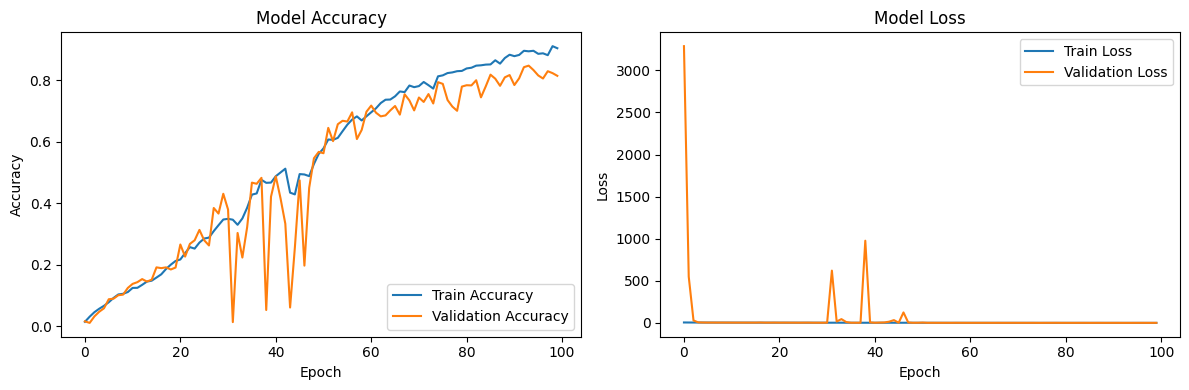

In [5]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_resnet.history['accuracy'], label='Train Accuracy')
plt.plot(history_resnet.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history_resnet.history['loss'], label='Train Loss')
plt.plot(history_resnet.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [6]:
# Export the Model and Class Mapping to /kaggle/working
model.save('/kaggle/working/botanical_model.h5')
print("Model saved as /kaggle/working/botanical_model.h5")

class_indices = df_train.class_indices
index_to_class = {int(v): str(k) for k, v in class_indices.items()}

with open('/kaggle/working/class_mapping.json', 'w') as f:
    json.dump(index_to_class, f)
print("Class mapping saved as /kaggle/working/class_mapping.json")

Model saved as /kaggle/working/botanical_model.h5
Class mapping saved as /kaggle/working/class_mapping.json


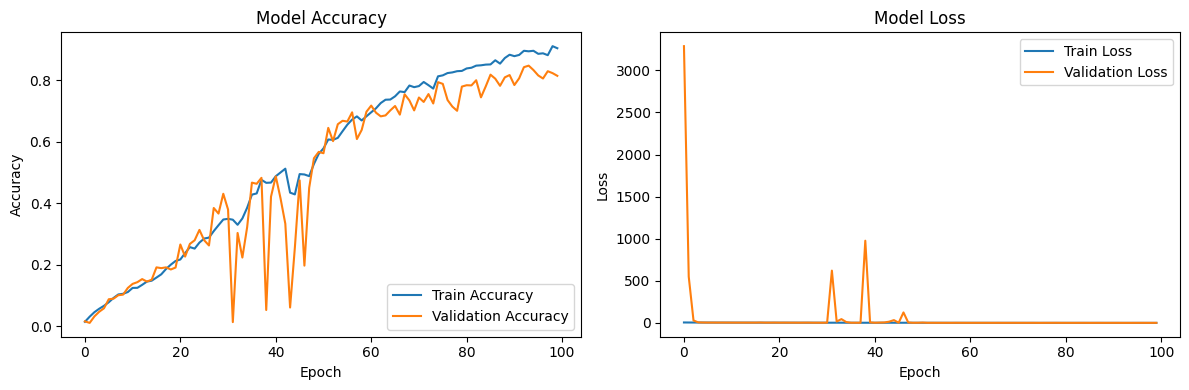

In [7]:
# Re-draw and save the plot as a PNG
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_resnet.history['accuracy'], label='Train Accuracy')
plt.plot(history_resnet.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history['loss'], label='Train Loss')
plt.plot(history_resnet.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper right')

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png')

In [8]:
import zipfile
import os
from IPython.display import FileLink

# Define the files you want to zip
files = ['botanical_model.h5', 'class_mapping.json', 'training_curves.png']
zip_name = 'flora_project_files.zip'

# Create the ZIP archive
with zipfile.ZipFile(zip_name, 'w') as zipf:
    for file in files:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Added {file} to zip.")
        else:
            print(f"Could not find {file}.")

# Generate the download link
display(FileLink(zip_name))

Added botanical_model.h5 to zip.
Added class_mapping.json to zip.
Added training_curves.png to zip.


/kaggle/working/flora_project_files.zip